### Import libraries

In [1]:
import os
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from sklearn.model_selection import train_test_split

### Load the LFAS dataset

In [2]:
src_dir = r"C:\Users\91861\OneDrive\Documents\LFAS\data\carla-capture-20180513A"

image_dir = os.path.join(src_dir, "CameraRGB")
mask_dir = os.path.join(src_dir, "CameraSeg")

print("Dataset folder exists :", os.path.exists(src_dir))
print("CameraRGB exists     :", os.path.exists(image_dir))
print("CameraSeg exists     :", os.path.exists(mask_dir))

image_names = sorted(os.listdir(image_dir))
mask_names = sorted(os.listdir(mask_dir))

print("Number of RGB images :", len(image_names))
print("Number of masks      :", len(mask_names))

print("\nFirst 5 RGB files:")
print(image_names[:5])

print("\nFirst 5 mask files:")
print(mask_names[:5])

Dataset folder exists : True
CameraRGB exists     : True
CameraSeg exists     : True
Number of RGB images : 1000
Number of masks      : 1000

First 5 RGB files:
['F61-1.png', 'F61-10.png', 'F61-100.png', 'F61-11.png', 'F61-12.png']

First 5 mask files:
['F61-1.png', 'F61-10.png', 'F61-100.png', 'F61-11.png', 'F61-12.png']


### DISPLAY ONE IMAGE AND MASK

Image shape: (600, 800, 3)
Mask shape : (600, 800, 3)
Mask unique values:
[0]


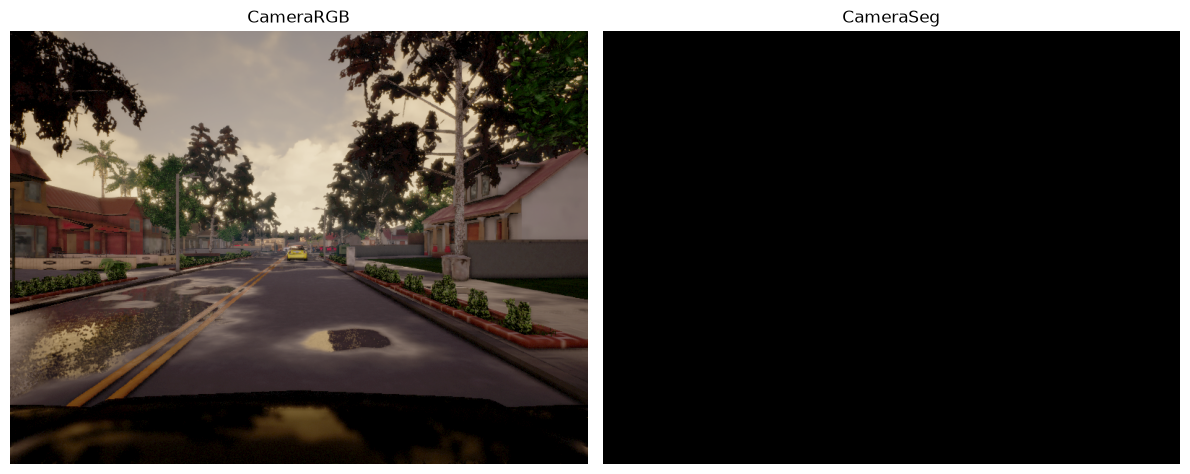

In [3]:
index = 0

image_path = os.path.join(image_dir, image_names[index])
mask_path = os.path.join(mask_dir, mask_names[index])

image = cv2.imread(image_path)
mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

print("Image shape:", image.shape)
print("Mask shape :", mask.shape)

if len(mask.shape) == 3:
    mask_display = mask[:, :, 0]
else:
    mask_display = mask

print("Mask unique values:")
print(np.unique(mask_display))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("CameraRGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask_display, cmap="gray")
plt.title("CameraSeg")
plt.axis("off")

plt.tight_layout()
plt.show()

### PREPARE IMAGES AND SEGMENTATION MASKS

In [4]:
IMG_HEIGHT = 272
IMG_WIDTH = 400

X = []
Y = []

num_samples = min(len(image_names), len(mask_names))

for i in range(num_samples):

    # Load image
    image_path = os.path.join(image_dir, image_names[i])
    image = cv2.imread(image_path)

    # Load mask
    mask_path = os.path.join(mask_dir, mask_names[i])
    mask = cv2.imread(mask_path, cv2.IMREAD_UNCHANGED)

    if image is None or mask is None:
        continue

    # Convert image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Resize image
    gray = cv2.resize(
        gray,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # Get one mask channel
    if len(mask.shape) == 3:
        mask = mask[:, :, 0]

    # Resize mask
    mask = cv2.resize(
        mask,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_NEAREST
    )

    # Create 4-class segmentation mask
    class_mask = np.zeros(
        (IMG_HEIGHT, IMG_WIDTH),
        dtype=np.uint8
    )

    # Existing LFAS mask mapping
    class_mask[mask == 6] = 1
    class_mask[mask == 7] = 2
    class_mask[mask == 8] = 3

    # Normalize input image
    gray = gray.astype(np.float32) / 255.0

    # Add channel dimension
    gray = np.expand_dims(gray, axis=-1)

    X.append(gray)
    Y.append(class_mask)

X = np.array(X, dtype=np.float32)
Y = np.array(Y, dtype=np.uint8)

print("Dataset preparation complete")
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Classes:", np.unique(Y))

Dataset preparation complete
X shape: (1000, 272, 400, 1)
Y shape: (1000, 272, 400)
Classes: [0]


### INSPECT ORIGINAL CAMERA SEGMENTATION MASK

In [5]:
index = 0

mask_path = os.path.join(mask_dir,
    mask_names[index]
)

raw_mask = cv2.imread(
    mask_path,
    cv2.IMREAD_UNCHANGED
)

print("Raw mask shape:", raw_mask.shape)
print("Raw mask dtype:", raw_mask.dtype)

# Show unique values for each channel
if len(raw_mask.shape) == 3:

    print("\nChannel 0 unique values:")
    print(np.unique(raw_mask[:, :, 0])[:100])

    print("\nChannel 1 unique values:")
    print(np.unique(raw_mask[:, :, 1])[:100])

    print("\nChannel 2 unique values:")
    print(np.unique(raw_mask[:, :, 2])[:100])

else:

    print("\nUnique values:")
    print(np.unique(raw_mask)[:100])

Raw mask shape: (600, 800, 3)
Raw mask dtype: uint8

Channel 0 unique values:
[0]

Channel 1 unique values:
[0]

Channel 2 unique values:
[ 0  1  2  3  4  5  6  7  8  9 10 11 12]


### DISPLAY ORIGINAL SEGMENTATION MASK

### CORRECT MASK CLASS EXTRACTION


In [6]:
IMG_HEIGHT = 272
IMG_WIDTH = 400

X = []
Y = []

num_samples = min(len(image_names), len(mask_names))

for i in range(num_samples):

    # LOAD RGB IMAGE
    
    image_path = os.path.join(
        image_dir,
        image_names[i]
    )

    image = cv2.imread(image_path)

    # LOAD SEGMENTATION MASK
    
    mask_path = os.path.join(
        mask_dir,
        mask_names[i]
    )

    raw_mask = cv2.imread(
        mask_path,
        cv2.IMREAD_UNCHANGED
    )

    if image is None or raw_mask is None:
        continue

    # IMAGE PREPROCESSING

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    gray = cv2.resize(
        gray,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # Normalize image
    gray = gray.astype(np.float32) / 255.0

    # Add channel dimension
    gray = np.expand_dims(
        gray,
        axis=-1
    )

    # MASK PREPROCESSING
    # CameraSeg class IDs are stored in channel 2
    
    mask = raw_mask[:, :, 2]

    # Resize using nearest-neighbor
    mask = cv2.resize(
        mask,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_NEAREST
    )

    # Keep original class IDs
    mask = mask.astype(np.uint8)

    X.append(gray)
    Y.append(mask)

# Convert to NumPy arrays
X = np.array(
    X,
    dtype=np.float32
)

Y = np.array(
    Y,
    dtype=np.uint8
)

print("Dataset preparation complete")
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Classes:", np.unique(Y))

Dataset preparation complete
X shape: (1000, 272, 400, 1)
Y shape: (1000, 272, 400)
Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]


### VISUALIZE CORRECTED MASK


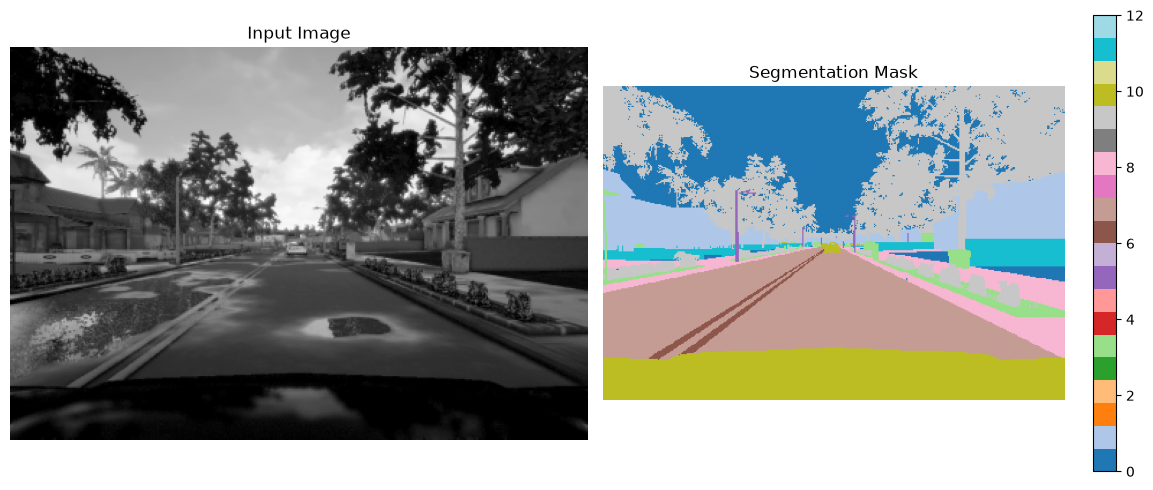

In [7]:
index = 0

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    X[index].squeeze(),
    cmap="gray"
)

plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 2, 2)

plt.imshow(
    Y[index],
    cmap="tab20"
)

plt.title("Segmentation Mask")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

### TRAIN TEST SPLIT

In [8]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y,test_size=0.20,random_state=42,shuffle=True)

print("Training images   :", X_train.shape)
print("Training masks    :", Y_train.shape)

print("Test images :", X_test.shape)
print("Test masks  :", Y_test.shape)

Training images   : (800, 272, 400, 1)
Training masks    : (800, 272, 400)
Test images : (200, 272, 400, 1)
Test masks  : (200, 272, 400)


### DETERMINE NUMBER OF SEGMENTATION CLASSES

In [9]:
classes = np.unique(Y)

NUM_CLASSES = len(classes)

print("Classes:", classes)
print("Number of classes:", NUM_CLASSES)

Classes: [ 0  1  2  3  4  5  6  7  8  9 10 11 12]
Number of classes: 13


### LFAS SEGMENTATION MODEL


In [10]:
model = models.Sequential([
    
    # Input
    layers.Input(
        shape=(IMG_HEIGHT, IMG_WIDTH, 1)
    ),

    # Encoder
    layers.Conv2D(32,(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Conv2D(64,(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128,(3, 3),
        activation="relu",
        padding="same"
    ),

    # Decoder
    layers.UpSampling2D(
        (2, 2)
    ),

    layers.Conv2D(64,(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D((2, 2)),

    # Pixel-level class prediction
    layers.Conv2D(
        NUM_CLASSES,
        (1, 1),
        activation="softmax",
        padding="same"
    )
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 272, 400, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 136, 200, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 136, 200, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 68, 100, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 68, 100, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 136, 200, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 136, 200, 64)   │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 272, 400, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 272, 400, 13)   │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 167,309 (653.55 KB)

 Trainable params: 167,309 (653.55 KB)

 Non-trainable params: 0 (0.00 B)

### COMPILE LFAS SEGMENTATION MODEL

In [11]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


### TEST MODEL OUTPUT


In [12]:
sample_input = X_train[:1]

sample_prediction = model.predict(
    sample_input,
    verbose=0
)

print("Input shape      :", sample_input.shape)
print("Prediction shape :", sample_prediction.shape)

Input shape      : (1, 272, 400, 1)
Prediction shape : (1, 272, 400, 13)


### TRAIN LFAS SEGMENTATION MODEL


In [13]:
checkpoint = ModelCheckpoint(
    "lfas_segmentation_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    X_train,Y_train,validation_data=(X_test, Y_test),
    epochs=10,
    batch_size=8,
    callbacks=[
        checkpoint,
        early_stopping
    ],
    verbose=1
)

Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.5211 - loss: 1.4000
Epoch 1: val_loss improved from None to 1.05871, saving model to lfas_segmentation_best.keras

Epoch 1: finished saving model to lfas_segmentation_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 225s 2s/step - accuracy: 0.5211 - loss: 1.4000 - val_accuracy: 0.6476 - val_loss: 1.0587
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6719 - loss: 0.9972
Epoch 2: val_loss improved from 1.05871 to 0.95894, saving model to lfas_segmentation_best.keras

Epoch 2: finished saving model to lfas_segmentation_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step - accuracy: 0.6719 - loss: 0.9972 - val_accuracy: 0.6786 - val_loss: 0.9589
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7023 - loss: 0.9129
Epoch 3: val_loss improved from 0.95894 to 0.89260, saving model to lfas_segmentation_best.keras

Epoch 3: finished saving model to lfas_segmentation_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 

In [14]:
print("Training completed.")

print("\nFinal training loss:", history.history["loss"][-1])
print("Final validation loss:", history.history["val_loss"][-1])

print("\nFinal training accuracy:", history.history["accuracy"][-1])
print("Final validation accuracy:", history.history["val_accuracy"][-1])

Training completed.

Final training loss: 0.647870659828186
Final validation loss: 0.6318367123603821

Final training accuracy: 0.7888191342353821
Final validation accuracy: 0.7904893755912781


### Visualize training performance

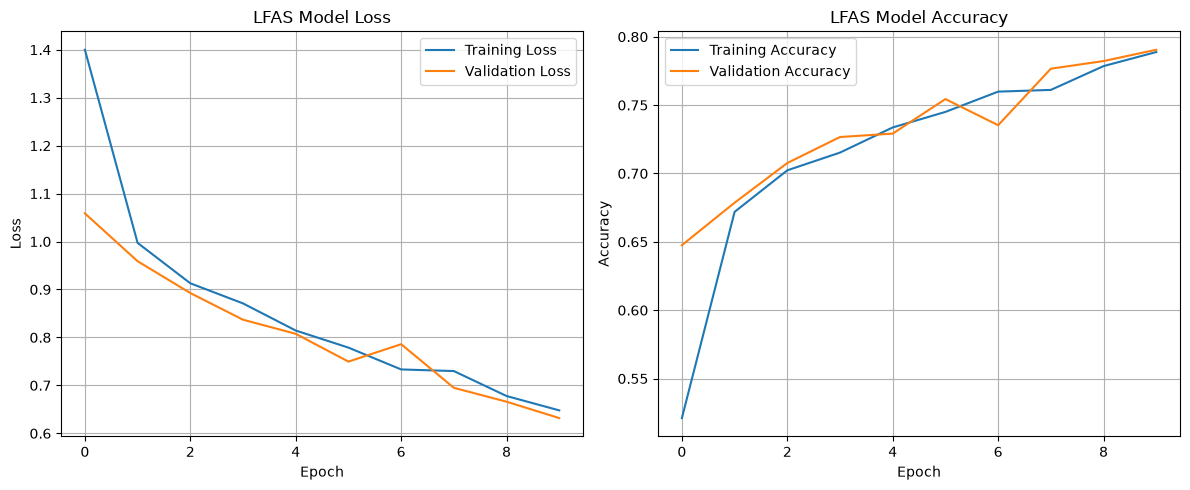

In [15]:
# Plot training and validation loss
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("LFAS Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Plot training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("LFAS Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Visualize the LFAS prediction

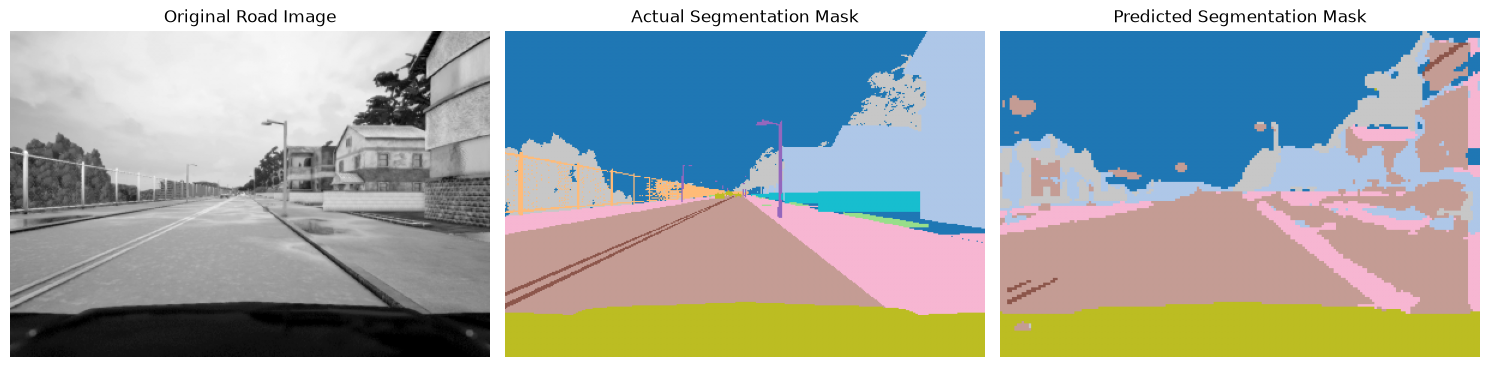

In [16]:
# Select one validation image
index = 0

# Get the image and its actual mask
test_image = X_test[index]
actual_mask = Y_test[index]

# Add batch dimension and predict
prediction = model.predict(
    np.expand_dims(test_image, axis=0),
    verbose=0
)

# Convert probabilities to class IDs
predicted_mask = np.argmax(prediction[0], axis=-1)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(test_image.squeeze(), cmap="gray")
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="tab20", vmin=0, vmax=12)
plt.title("Actual Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="tab20", vmin=0, vmax=12)
plt.title("Predicted Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

### Calculate Intersection over Union (IoU)

In [17]:
# Predict masks for the validation dataset
predictions = model.predict(X_test, batch_size=8, verbose=1)

# Convert predicted probabilities into class IDs
predicted_masks = np.argmax(predictions, axis=-1)

# Calculate mean IoU
miou_metric = tf.keras.metrics.MeanIoU(num_classes=NUM_CLASSES)

miou_metric.update_state(
    Y_test.flatten(),
    predicted_masks.flatten()
)

print("Mean IoU:", round(float(miou_metric.result().numpy()), 4))

25/25 ━━━━━━━━━━━━━━━━━━━━ 13s 480ms/step
Mean IoU: 0.3027


In [18]:
# Calculate IoU separately for every class
class_iou = tf.keras.metrics.IoU(
    num_classes=NUM_CLASSES,
    target_class_ids=list(range(NUM_CLASSES))
)

class_iou.update_state(
    Y_test.flatten(),
    predicted_masks.flatten()
)

# Get the confusion matrix to calculate per-class IoU
confusion = tf.math.confusion_matrix(
    Y_test.flatten(),
    predicted_masks.flatten(),
    num_classes=NUM_CLASSES
).numpy()

intersection = np.diag(confusion)
union = (
    confusion.sum(axis=0)
    + confusion.sum(axis=1)
    - intersection
)

iou_per_class = np.divide(
    intersection,
    union,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=union != 0
)

for class_id, score in enumerate(iou_per_class):
    print(f"Class {class_id}: IoU = {score:.4f}")

print("\nMean IoU:", round(float(np.mean(iou_per_class)), 4))

Class 0: IoU = 0.8708
Class 1: IoU = 0.3530
Class 2: IoU = 0.0046
Class 3: IoU = 0.0009
Class 4: IoU = 0.0000
Class 5: IoU = 0.0087
Class 6: IoU = 0.2142
Class 7: IoU = 0.6246
Class 8: IoU = 0.3664
Class 9: IoU = 0.5872
Class 10: IoU = 0.8835
Class 11: IoU = 0.0213
Class 12: IoU = 0.0000

Mean IoU: 0.3027


### Check class distribution

In [19]:
# Count pixels belonging to each class
actual_counts = np.bincount(
    Y_test.flatten(),
    minlength=NUM_CLASSES
)

predicted_counts = np.bincount(
    predicted_masks.flatten(),
    minlength=NUM_CLASSES
)

print("Class distribution on validation data\n")

for class_id in range(NUM_CLASSES):
    print(
        f"Class {class_id:2d} | "
        f"Actual pixels: {actual_counts[class_id]:9d} | "
        f"Predicted pixels: {predicted_counts[class_id]:9d}"
    )

Class distribution on validation data

Class  0 | Actual pixels:   6921756 | Predicted pixels:   6563056
Class  1 | Actual pixels:   1807453 | Predicted pixels:   1835788
Class  2 | Actual pixels:    160625 | Predicted pixels:      1292
Class  3 | Actual pixels:    230620 | Predicted pixels:       392
Class  4 | Actual pixels:      4853 | Predicted pixels:         0
Class  5 | Actual pixels:    108867 | Predicted pixels:      2192
Class  6 | Actual pixels:    169692 | Predicted pixels:     51984
Class  7 | Actual pixels:   4341950 | Predicted pixels:   5573376
Class  8 | Actual pixels:   1798155 | Predicted pixels:   1230052
Class  9 | Actual pixels:   2543283 | Predicted pixels:   3115784
Class 10 | Actual pixels:   3469911 | Predicted pixels:   3375760
Class 11 | Actual pixels:    192037 | Predicted pixels:     10324
Class 12 | Actual pixels:     10798 | Predicted pixels:         0


### Improve learning for less-common classes

In [20]:
# Count class pixels in the training dataset only
class_counts = np.bincount(
    Y_train.flatten(),
    minlength=NUM_CLASSES
)

# Calculate balanced weights using inverse square root frequency
class_weights = np.zeros(NUM_CLASSES, dtype=np.float32)

present = class_counts > 0
class_weights[present] = np.sqrt(
    class_counts[present].sum()
    / (NUM_CLASSES * class_counts[present])
)

# Limit extreme weights to keep training stable
class_weights = np.minimum(class_weights, 5.0)
class_weights = class_weights / class_weights.mean()

print("Class weights:")
for class_id, weight in enumerate(class_weights):
    print(f"Class {class_id}: {weight:.3f}")

weights_tensor = tf.constant(class_weights, dtype=tf.float32)

# Define a loss that gives different importance to each pixel class
def weighted_sparse_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.int32)

    pixel_loss = tf.keras.losses.sparse_categorical_crossentropy(
        y_true, y_pred
    )

    pixel_weights = tf.gather(weights_tensor, y_true)

    return tf.reduce_mean(pixel_loss * pixel_weights)

# Compile the existing model with the new loss
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss=weighted_sparse_loss,
    metrics=["accuracy"]
)

# Save the best model from this new training run
checkpoint_weighted = ModelCheckpoint(
    "lfas_weighted_best.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

early_stopping_weighted = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

# Continue training from the model's current weights
history_weighted = model.fit(
    X_train,
    Y_train,
    validation_data=(X_test, Y_test),
    epochs=10,
    batch_size=8,
    callbacks=[checkpoint_weighted, early_stopping_weighted],
    verbose=1
)

Class weights:
Class 0: 0.208
Class 1: 0.412
Class 2: 1.478
Class 3: 1.077
Class 4: 2.114
Class 5: 1.667
Class 6: 1.329
Class 7: 0.263
Class 8: 0.406
Class 9: 0.342
Class 10: 0.292
Class 11: 1.298
Class 12: 2.114
Epoch 1/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7982 - loss: 0.3034
Epoch 1: val_loss improved from None to 0.30266, saving model to lfas_weighted_best.keras

Epoch 1: finished saving model to lfas_weighted_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 252s 2s/step - accuracy: 0.7982 - loss: 0.3034 - val_accuracy: 0.7968 - val_loss: 0.3027
Epoch 2/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8011 - loss: 0.2953
Epoch 2: val_loss improved from 0.30266 to 0.29851, saving model to lfas_weighted_best.keras

Epoch 2: finished saving model to lfas_weighted_best.keras
100/100 ━━━━━━━━━━━━━━━━━━━━ 347s 3s/step - accuracy: 0.8011 - loss: 0.2953 - val_accuracy: 0.7985 - val_loss: 0.2985
Epoch 3/10
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8037 - loss: 

### Re-evaluate the trained model

In [22]:
# Predict all validation images using the updated model
predictions_weighted = model.predict(
    X_test,
    batch_size=8,
    verbose=1
)

# Convert probabilities to class IDs
predicted_masks_weighted = np.argmax(
    predictions_weighted,
    axis=-1
)

# Calculate per-class IoU
confusion_weighted = tf.math.confusion_matrix(
    Y_test.flatten(),
    predicted_masks_weighted.flatten(),
    num_classes=NUM_CLASSES
).numpy()

intersection_weighted = np.diag(confusion_weighted)

union_weighted = (
    confusion_weighted.sum(axis=0)
    + confusion_weighted.sum(axis=1)
    - intersection_weighted
)

iou_weighted = np.divide(
    intersection_weighted,
    union_weighted,
    out=np.zeros(NUM_CLASSES, dtype=float),
    where=union_weighted != 0
)

for class_id, score in enumerate(iou_weighted):
    print(f"Class {class_id}: IoU = {score:.4f}")

print("\nWeighted Mean IoU:", round(float(iou_weighted.mean()), 4))

25/25 ━━━━━━━━━━━━━━━━━━━━ 18s 670ms/step
Class 0: IoU = 0.8820
Class 1: IoU = 0.3890
Class 2: IoU = 0.1175
Class 3: IoU = 0.0474
Class 4: IoU = 0.0000
Class 5: IoU = 0.1118
Class 6: IoU = 0.3461
Class 7: IoU = 0.6681
Class 8: IoU = 0.4550
Class 9: IoU = 0.6064
Class 10: IoU = 0.8942
Class 11: IoU = 0.0836
Class 12: IoU = 0.0000

Weighted Mean IoU: 0.3539


### Visualize the improved predictions

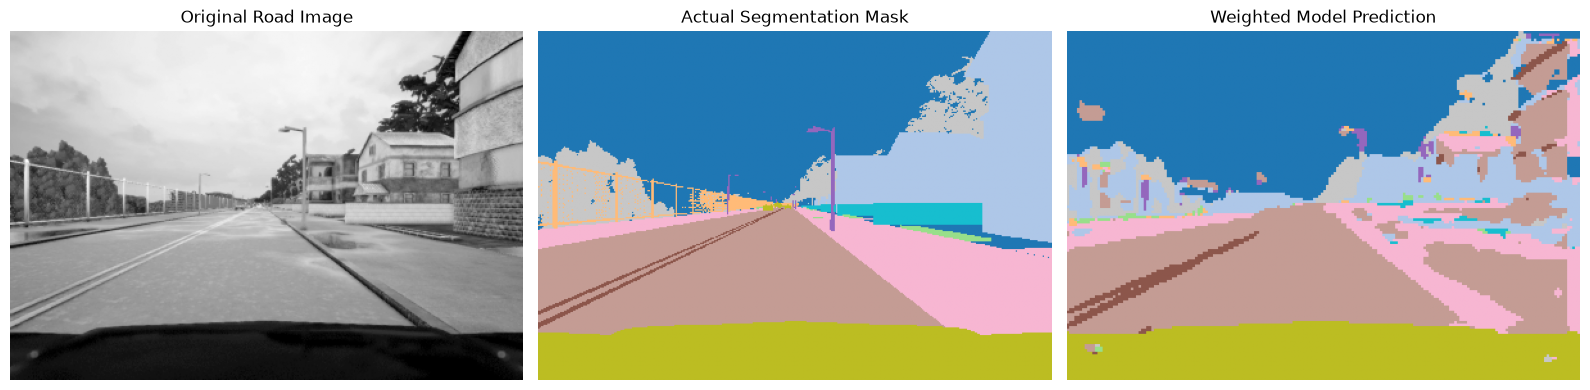

In [24]:
# Select a validation image
index = 0

test_image = X_test[index]
actual_mask = Y_test[index]
predicted_mask = predicted_masks_weighted[index]

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(test_image.squeeze(), cmap="gray")
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(actual_mask, cmap="tab20", vmin=0, vmax=12)
plt.title("Actual Segmentation Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(predicted_mask, cmap="tab20", vmin=0, vmax=12)
plt.title("Weighted Model Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
# Save the current model
model.save("lfas_weighted_final.keras")

print("LFAS model saved successfully!")
print("File: lfas_weighted_final.keras")

LFAS model saved successfully!
File: lfas_weighted_final.keras
